# Problema 2 — Rede MLP em PyTorch para Detecção de Ataques em Redes (NSL-KDD)

**Dataset:** NSL-KDD (`KDDTrain+.txt` com 125.973 conexões e `KDDTest+.txt` com 22.544 conexões). Classificação binária: `0` (normal) vs `1` (ataque).

In [5]:
from pathlib import Path
import copy
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})
print(f"Dispositivo: {DEVICE}")

Dispositivo: cpu


## 1. Preparação dos Dados

- Carregamento com os 43 rótulos de coluna e descarte de `difficulty_level`.
- *One-hot encoding* em `protocol_type`, `service` e `flag`.
- Binarização do rótulo (`normal` → `0`, qualquer ataque → `1`).
- Divisão 80% treino / 20% validação e normalização *Z-score* dos atributos numéricos ajustada **apenas** no conjunto de treino.

In [6]:
col_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised", "root_shell",
    "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "attack_type", "difficulty_level"
]

data_dir = Path("data/nsl-kdd")
data_dir.mkdir(parents=True, exist_ok=True)
base_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master"
for fname in ("KDDTrain+.txt", "KDDTest+.txt"):
    fpath = data_dir / fname
    if not fpath.exists():
        urllib.request.urlretrieve(f"{base_url}/{fname.replace('+', '%2B')}", fpath)

train_df = pd.read_csv(data_dir / "KDDTrain+.txt", names=col_names).drop(columns=["difficulty_level"])
test_df = pd.read_csv(data_dir / "KDDTest+.txt", names=col_names).drop(columns=["difficulty_level"])

y_train_full = (train_df.pop("attack_type") != "normal").astype(np.float32).to_numpy()
y_test = (test_df.pop("attack_type") != "normal").astype(np.float32).to_numpy()

cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in train_df.columns if c not in cat_cols]

# One-hot encoding alinhado pelo esquema do conjunto de treino
X_train_enc = pd.get_dummies(train_df, columns=cat_cols, dtype=np.float32)
X_test_enc = pd.get_dummies(test_df, columns=cat_cols, dtype=np.float32).reindex(
    columns=X_train_enc.columns, fill_value=0.0
)

# Reserva de 20% do treino como validação (estratificada, sem embaralhamento no DataLoader)
X_tr_df, X_val_df, y_tr, y_val = train_test_split(
    X_train_enc, y_train_full, test_size=0.2, stratify=y_train_full, random_state=SEED
)

# Padronização Z-score apenas nos atributos numéricos com estatísticas do treino
scaler = StandardScaler()
X_tr_df, X_val_df, X_test_enc = X_tr_df.copy(), X_val_df.copy(), X_test_enc.copy()
X_tr_df[num_cols] = scaler.fit_transform(X_tr_df[num_cols])
X_val_df[num_cols] = scaler.transform(X_val_df[num_cols])
X_test_enc[num_cols] = scaler.transform(X_test_enc[num_cols])

X_tr = X_tr_df.to_numpy(dtype=np.float32)
X_val = X_val_df.to_numpy(dtype=np.float32)
X_test = X_test_enc.to_numpy(dtype=np.float32)

print(f"Treino: {X_tr.shape} (ataques: {y_tr.mean():.1%})")
print(f"Validação: {X_val.shape} (ataques: {y_val.mean():.1%})")
print(f"Teste: {X_test.shape} (ataques: {y_test.mean():.1%})")

BATCH_SIZE = 256
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test)), batch_size=BATCH_SIZE, shuffle=False)

Treino: (100778, 122) (ataques: 46.5%)
Validação: (25195, 122) (ataques: 46.5%)
Teste: (22544, 122) (ataques: 56.9%)


## 2. Implementação da MLP em PyTorch

Classe `MLP(nn.Module)` flexível para testar diferentes topologias (camadas ocultas, ativação e *dropout*), mantendo a saída linear (sem sigmoide) para uso direto com `BCEWithLogitsLoss`.

In [7]:
class MLP(nn.Module):
    def __init__(self, in_features, hidden_dims, activation="relu", dropout=0.0):
        super().__init__()
        act_cls = {"relu": nn.ReLU, "leaky_relu": nn.LeakyReLU, "gelu": nn.GELU}[activation]
        layers = []
        prev = in_features
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), act_cls()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))  # logit sem ativação
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def evaluate_loss(model, loader, criterion):
    model.eval()
    total_loss, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            loss = criterion(model(xb), yb)
            total_loss += loss.item() * len(xb)
            n += len(xb)
    return total_loss / n


def train_mlp(hidden_dims, activation="relu", dropout=0.0, epochs=50, lr=1e-3, patience=10):
    torch.manual_seed(SEED)
    model = MLP(X_tr.shape[1], hidden_dims, activation=activation, dropout=dropout).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    best_val, best_epoch, best_state = float("inf"), 0, None
    no_improve = 0

    for epoch in range(1, epochs + 1):
        model.train()
        running, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
            n += len(xb)

        tr_loss = running / n
        va_loss = evaluate_loss(model, val_loader, criterion)
        train_losses.append(tr_loss)
        val_losses.append(va_loss)

        if va_loss < best_val:
            best_val, best_epoch = va_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

    model.load_state_dict(best_state)
    return {
        "model": model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val": best_val,
        "best_epoch": best_epoch,
        "early_stop_epoch": next((i + 1 for i in range(best_epoch, epochs) if i - best_epoch >= patience), epochs),
    }

## 3. Estudo de Topologias, Treinamento e Monitoramento (50 épocas)

In [ ]:
configs = {
    "MLP [64, 32] ReLU": dict(hidden_dims=[64, 32], activation="relu", dropout=0.0),
    "MLP [128, 64] ReLU + Drop(0.2)": dict(hidden_dims=[128, 64], activation="relu", dropout=0.2),
    "MLP [128, 64, 32] LeakyReLU + Drop(0.2)": dict(hidden_dims=[128, 64, 32], activation="leaky_relu", dropout=0.2),
}

experiments = {}
summary_rows = []
for name, cfg in configs.items():
    res = train_mlp(**cfg, epochs=50, lr=1e-3)
    experiments[name] = res
    summary_rows.append({
        "Arquitetura": name,
        "Melhor Val Loss": res["best_val"],
        "Melhor Época": res["best_epoch"],
        "Train Loss (Ép. 50)": res["train_losses"][-1],
        "Val Loss (Ép. 50)": res["val_losses"][-1],
    })

summary_df = pd.DataFrame(summary_rows).sort_values("Melhor Val Loss")
display(summary_df)

best_name = summary_df.iloc[0]["Arquitetura"]
best_exp = experiments[best_name]
print(f"\nMelhor arquitetura na validação: {best_name} (época {best_exp['best_epoch']}, val_loss={best_exp['best_val']:.5f})")

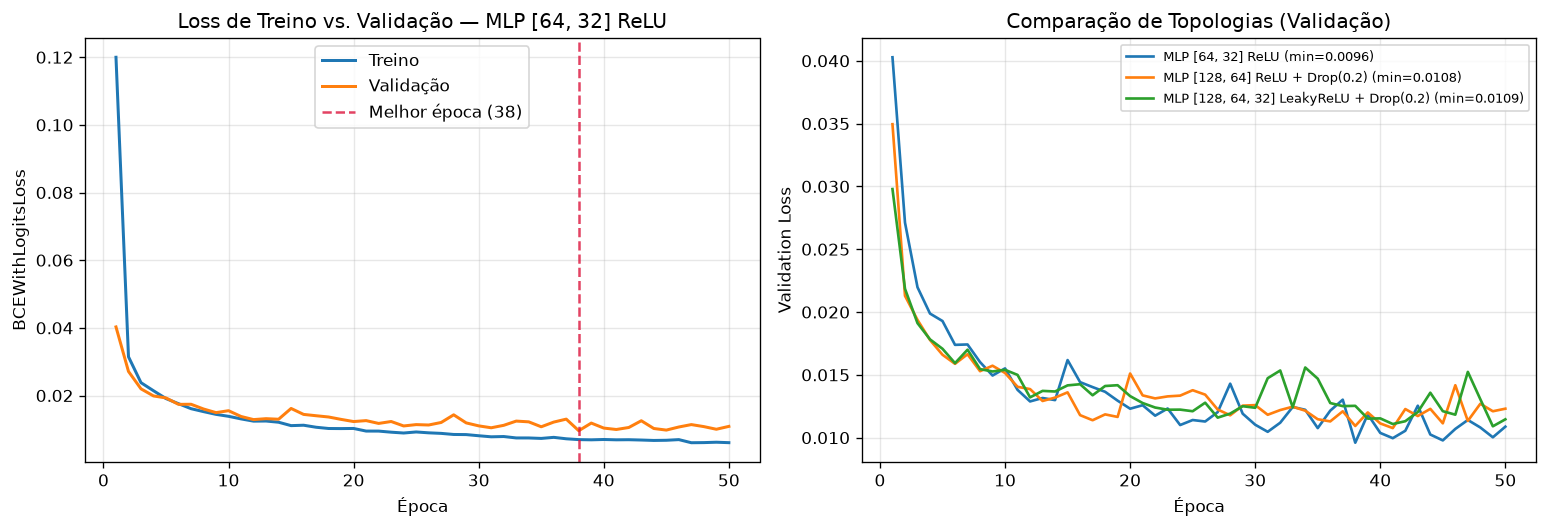

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, 51)

# Curvas de treino e validação da melhor arquitetura
axes[0].plot(epochs_range, best_exp["train_losses"], label="Treino", lw=1.8)
axes[0].plot(epochs_range, best_exp["val_losses"], label="Validação", lw=1.8)
axes[0].axvline(best_exp["best_epoch"], color="crimson", ls="--", alpha=0.8, label=f"Melhor época ({best_exp['best_epoch']})")
axes[0].set(title=f"Loss de Treino vs. Validação — {best_name}", xlabel="Época", ylabel="BCEWithLogitsLoss")
axes[0].legend()

# Comparação das curvas de validação entre as arquiteturas
for name, res in experiments.items():
    axes[1].plot(epochs_range, res["val_losses"], label=f"{name} (min={res['best_val']:.4f})", lw=1.6)
axes[1].set(title="Comparação de Topologias (Validação)", xlabel="Época", ylabel="Validation Loss")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. Avaliação Final no Conjunto de Teste (`KDDTest+.txt`)

Acurácia : 0.7849
Precisão : 0.9246
Recall   : 0.6774
F1-score : 0.7819

              precision    recall  f1-score   support

  Normal (0)     0.6850    0.9270    0.7878      9711
  Ataque (1)     0.9246    0.6774    0.7819     12833

    accuracy                         0.7849     22544
   macro avg     0.8048    0.8022    0.7849     22544
weighted avg     0.8214    0.7849    0.7845     22544

Análise de limiar de decisão (trade-off FN vs FP):
  limiar=0.1 | Acc=0.8203 | Prec=0.9270 | Rec=0.7427 | F1=0.8247 | FN=3302 | FP=750
  limiar=0.2 | Acc=0.8139 | Prec=0.9275 | Rec=0.7301 | F1=0.8171 | FN=3463 | FP=732
  limiar=0.3 | Acc=0.7947 | Prec=0.9253 | Rec=0.6955 | F1=0.7941 | FN=3908 | FP=721


  limiar=0.5 | Acc=0.7849 | Prec=0.9246 | Rec=0.6774 | F1=0.7819 | FN=4140 | FP=709
  limiar=0.7 | Acc=0.7760 | Prec=0.9240 | Rec=0.6610 | F1=0.7706 | FN=4351 | FP=698


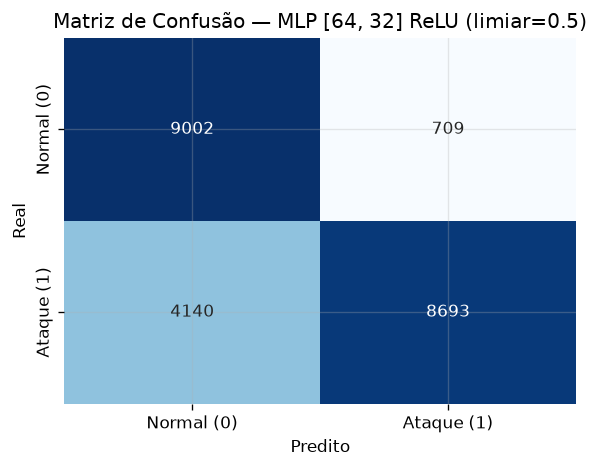

In [ ]:
best_model = best_exp["model"]
best_model.eval()
probs_list = []
with torch.no_grad():
    for xb, _ in test_loader:
        probs_list.append(torch.sigmoid(best_model(xb.to(DEVICE))).cpu().numpy())

y_prob = np.concatenate(probs_list)
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Acurácia : {acc:.4f}")
print(f"Precisão : {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Ataque (1)"], digits=4))

# Sensibilidade ao limiar de decisão
print("Análise de limiar de decisão (trade-off FN vs FP):")
for thr in [0.1, 0.2, 0.3, 0.5, 0.7]:
    yp = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    print(f"  limiar={thr:.1f} | Acc={accuracy_score(y_test, yp):.4f} | Prec={precision_score(y_test, yp):.4f} | Rec={recall_score(y_test, yp):.4f} | F1={f1_score(y_test, yp):.4f} | FN={fn} | FP={fp}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Normal (0)", "Ataque (1)"],
    yticklabels=["Normal (0)", "Ataque (1)"], ax=ax
)
ax.set(title=f"Matriz de Confusão — {best_name} (limiar=0.5)", xlabel="Predito", ylabel="Real")
plt.tight_layout()
plt.show()